# Line Chart (multiset 2)
- Average Revenue Growth per Retained User
- Retention Decay vs Monetization Growth

In [1]:
import pandas as pd
# Настройка отображения
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.width', None)
pd.set_option('display.max_columns', None)

## Исходные данные для построения

In [2]:
rpru_table = pd.read_parquet('rpru_table.parquet')
user_retention = pd.read_parquet('user_retention.parquet')

In [3]:
print(rpru_table)

cohort_index    0     1     2     3     4     5     6     7     8     9     10
cohort_month                                                                  
2021-07-01    1.29  1.90  1.53  2.04  1.91  1.78  2.03  1.63  2.13  1.74  1.85
2021-08-01    1.14  1.26  1.29  1.38  1.36  1.38  1.44  1.89  1.19  1.34   NaN
2021-09-01    1.30  1.63  1.50  1.70  1.36  1.48  1.71  1.36  1.37   NaN   NaN
2021-10-01    1.35  1.61  1.61  1.71  1.47  1.20  1.33  1.24   NaN   NaN   NaN
2021-11-01    1.44  1.31  1.56  1.28  1.20  1.22  1.08   NaN   NaN   NaN   NaN
2021-12-01    1.26  1.33  1.33  1.06  1.26  1.05   NaN   NaN   NaN   NaN   NaN
2022-01-01    1.26  1.46  2.08  1.34  1.33   NaN   NaN   NaN   NaN   NaN   NaN
2022-02-01    1.36  1.42  1.35  1.29   NaN   NaN   NaN   NaN   NaN   NaN   NaN
2022-03-01    1.56  1.17  1.47   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
2022-04-01    1.31  2.13   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
2022-05-01    1.34   NaN   NaN   NaN   NaN   NaN   N

In [4]:
print(user_retention)

cohort_index   0         1         2         3         4         5         6         7         8         9         10
cohort_month                                                                                                         
2021-07       1.0  0.333876  0.345277  0.317590  0.328990  0.294788  0.280130  0.289902  0.270358  0.254072  0.239414
2021-08       1.0  0.284257  0.298834  0.253644  0.252187  0.233236  0.214286  0.204082  0.202624  0.172012       NaN
2021-09       1.0  0.301435  0.244019  0.223285  0.247209  0.186603  0.204147  0.189793  0.178628       NaN       NaN
2021-10       1.0  0.245115  0.266430  0.227353  0.202487  0.181172  0.179396  0.158082       NaN       NaN       NaN
2021-11       1.0  0.275100  0.204819  0.222892  0.198795  0.174699  0.176707       NaN       NaN       NaN       NaN
2021-12       1.0  0.190570  0.200393  0.161100  0.155206  0.149312       NaN       NaN       NaN       NaN       NaN
2022-01       1.0  0.218341  0.216157  0.189956  0.17030

## Код для построения

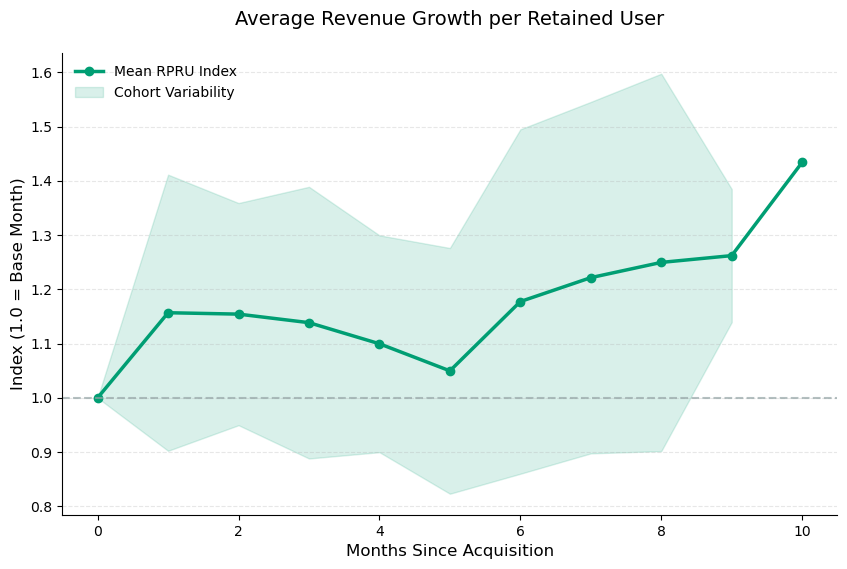

In [5]:
# =====================================================
# IMPORTS
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# The meaning of colors
# =====================================================

POSITIVE = '#009E73'
NEGATIVE = '#D55E00'
USERS = '#4C72B0'

# =====================================================
# DATA PREPARATION
# =====================================================

rpru_growth = rpru_table.divide(rpru_table[0], axis=0)

# =====================================================
# PLOT
# =====================================================

# Рассчитываем среднее и стандартное отклонение для "зоны уверенности"
mean_growth = rpru_growth.mean()
std_growth = rpru_growth.std()

plt.figure(figsize=(10, 6))

# Рисуем линию
plt.plot(mean_growth.index, mean_growth.values, marker='o', 
         linewidth=2.5, color=POSITIVE, label='Mean RPRU Index')  #2c3e50

# Добавляем "зону уверенности" (Confidence Interval) - это признак уровня Senior
plt.fill_between(mean_growth.index, 
                 mean_growth - std_growth, 
                 mean_growth + std_growth, 
                 color= POSITIVE, alpha=0.15, label='Cohort Variability') #3498db

# Базовая линия (уже есть, делаем её акцентной)
plt.axhline(y=1, linestyle='--', color='#95a5a6', alpha=0.7)

# Оформление
plt.title('Average Revenue Growth per Retained User', 
          fontsize=14, pad=20)
plt.ylabel('Index (1.0 = Base Month)', fontsize=12)
plt.xlabel('Months Since Acquisition', fontsize=12)

# Убираем лишние "рамки"
plt.gca().spines[['top', 'right']].set_visible(False)
plt.grid(axis='y', linestyle='--', alpha=0.3) #plt.grid(axis='y', linestyle=':', alpha=0.6)

plt.legend(frameon=False)
plt.savefig("average_rpru_growth_curve.png", dpi=300, bbox_inches="tight")
plt.show()

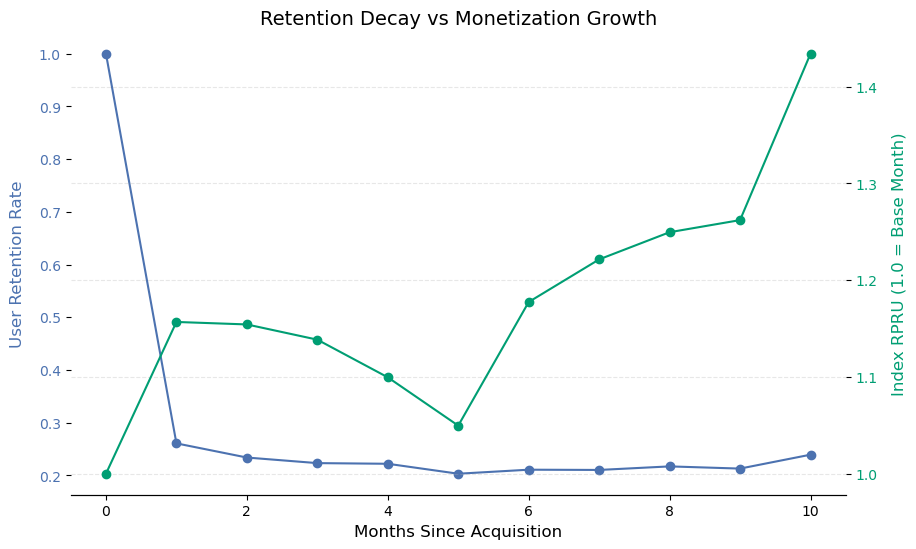

In [6]:
# =====================================================
# DATA PREPARATION
# =====================================================

mature_user_retention = user_retention.iloc[:-2]
mature_rpru_table = rpru_table.iloc[:-2]
avg_user_retention = mature_user_retention.mean()

# =====================================================
# AVERAGE REVENUE PER RETAINED USER
# =====================================================

avg_rpru = mature_rpru_table.mean()

# =====================================================
# PLOT
# =====================================================

fig, ax1 = plt.subplots(figsize=(10,6))

ax1.plot(
    avg_user_retention.index,
    avg_user_retention.values,
    color=USERS,
    marker='o'
)

ax1.set_xlabel('Months Since Acquisition', fontsize=12)
ax1.set_ylabel('User Retention Rate', color=USERS, fontsize=12, labelpad = 10)
ax1.tick_params(axis='y', labelcolor=USERS)

ax2 = ax1.twinx()

ax2.plot(
    mean_growth.index,
    mean_growth.values,
    color=POSITIVE,
    marker='o'
)

ax2.set_ylabel('Index RPRU (1.0 = Base Month)', color=POSITIVE, fontsize=12, labelpad = 10)
ax2.tick_params(axis='y', labelcolor=POSITIVE)

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_visible(False)

plt.title('Retention Decay vs Monetization Growth', fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.3) 
plt.savefig("retention_vs_monetization.png", dpi=300, bbox_inches="tight")
plt.show()